<a href="https://colab.research.google.com/github/George7531/Portfolio_Management/blob/main/Group_19296_MScFE_652_Portfolio_Management_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Group Work Project # 1**
###**GROUP NUMBER: 19296**
##**Group members:**
- George Immanuel
- Sing Chun Lee
- Duy Vo

#### Import Required Packages

In [ ]:
# This block import all required python packages for running this notebook
import numpy as np                      # numpy
import matplotlib.pyplot as plt         # for plotting
import math                             # math lib
import pandas as pd                     # for storing data in the DataFrame
import pandas_datareader.data as web
from scipy.optimize import minimize     # for minimizing
import yfinance as yf                   # yfinance library

# Data Preperation and Description

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web

# Define parameters
tickers = ['TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM']
BENCHMARK = "^GSPC"
in_sample_start = '2023-09-01'
in_sample_end = '2025-09-30'
out_sample_start = '2025-10-01'
out_sample_end = '2025-12-31'

# 1. Download using yfinance
# Using auto_adjust=False
raw_data = yf.download(
    tickers + [BENCHMARK],
    start='2023-08-25', # For initial return
    end='2026-01-01', # the end is exclusive, we should use 2026-01-01 so 2025-12-31 is included
    auto_adjust=False
)

adj_close = raw_data['Close']

# Calculate simple daily percentage returns
daily_returns = adj_close.pct_change().dropna(how='all')

# Drop any trading days where any of the 10 assets have missing data (strict alignment)
daily_returns = daily_returns.dropna()

# In-Sample and Out-of-Sample subsets
returns_in_sample = daily_returns.loc[in_sample_start:in_sample_end]
returns_out_sample = daily_returns.loc[out_sample_start:out_sample_end]

print(f"In-Sample Observations: {len(returns_in_sample)} days")
print(f"Out-of-Sample Observations: {len(returns_out_sample)} days")

# 2. Download Fama-French 5-Factor Daily Data
ff5_daily = web.DataReader('F-F_Research_Data_5_Factors_2x3_daily', 'famafrench', start='2023-09-01', end='2026-01-01')[0]

# Convert from percentages to decimals
ff5_daily = ff5_daily / 100.0

# Partition factor data
ff_in_sample = ff5_daily.loc[in_sample_start:in_sample_end]
ff_out_sample = ff5_daily.loc[out_sample_start:out_sample_end]

print("\nFama-French Data Sample:")
print(pd.concat([ff_in_sample.head(2), ff_out_sample.tail(3)]))

[*********************100%***********************]  11 of 11 completed


In-Sample Observations: 521 days
Out-of-Sample Observations: 64 days

Fama-French Data Sample:
            Mkt-RF     SMB     HML     RMW     CMA      RF
Date                                                      
2023-09-01  0.0026  0.0085  0.0058  0.0000 -0.0022  0.0002
2023-09-05 -0.0054 -0.0157 -0.0087 -0.0030 -0.0048  0.0002
2025-12-29 -0.0041 -0.0015  0.0007  0.0032  0.0003  0.0002
2025-12-30 -0.0020 -0.0049  0.0029  0.0036  0.0014  0.0002
2025-12-31 -0.0076  0.0006 -0.0010 -0.0007 -0.0004  0.0002


# Part 1 (Standard mean-variance portfolio optimization)

In [ ]:
## Step 1: Determine the weights
num_trading_days = 252 # assume there are about 252 trading days a year, which is the default in the package: https://pyportfolioopt.readthedocs.io/en/latest/ExpectedReturns.html
n = len(tickers)
w0 = np.ones(n) / n # initial weights

# compute the annual expected return, covariance, and risk free rate
mean = returns_in_sample[tickers].mean().values * num_trading_days
cov = returns_in_sample[tickers].cov().values * num_trading_days
rf = ff_in_sample['RF'].mean() * num_trading_days

# constraints
constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1} # make sure weight sum is equal to 1
bounds = [(0, 1)] * n # no short-selling constraint is achieved by weight bounds

# define portfolio return, volatility, and Sharpe ratio for the optimization
portfolio_return = lambda w: w @ mean
portfolio_volatility = lambda w: np.sqrt(w @ cov @ w)
sharpe_ratio = lambda w: (portfolio_return(w) - rf) / portfolio_volatility(w)

# mean-variance portfolio optimization with the given constraints
gmv = minimize(lambda w: w @ cov @ w, w0, method='SLSQP', constraints=constraints, bounds=bounds) # global minimum variance one
msr = minimize(lambda w: -sharpe_ratio(w), w0, method='SLSQP', constraints=constraints, bounds=bounds) # maximum Sharpe ratio one
mvo = minimize(lambda w: 0.5 * (w @ cov @ w) - w @ mean, w0, method='SLSQP', constraints=constraints, bounds=bounds) # mean-variance
assert gmv.success and msr.success and mvo.success, f"Errors: {gmv.message}, {msr.message}, {mvo.message}"

# results
weights = pd.DataFrame({'Min Var': gmv.x, 'Max Sharpe': msr.x, 'Mean Variance': mvo.x}, index=tickers)
print("Optimal Portfolio Weights (%):")
print((weights * 100).round(2))

# check if the constraints met
print("\nSum of Weights:", weights.sum().round(2))
print("\nNo short-selling:", (weights >= 0).all())

Optimal Portfolio Weights (%):
      Min Var  Max Sharpe  Mean Variance
TSLA     0.00        0.00           0.00
WMT     28.68       43.69           0.00
BAC      4.15        0.00           0.00
GS       0.00       34.65          43.13
LLY      3.08        0.00           0.00
MRK     22.47        0.00           0.00
GOOG    13.44        4.95           0.00
META     0.28       16.70          56.87
AAPL     0.34        0.00           0.00
XOM     27.57        0.00           0.00

Sum of Weights: Min Var          1.0
Max Sharpe       1.0
Mean Variance    1.0
dtype: float64

No short-selling: Min Var          True
Max Sharpe       True
Mean Variance    True
dtype: bool


In [ ]:
## Step 2: Bounded by 0.18
bounds = [(0, 0.18)] * n # bound the weights by 18%

# recompute the weights
mvo_new = minimize(lambda w: 0.5 * (w @ cov @ w) - w @ mean, w0, method='SLSQP', constraints=constraints, bounds=bounds) # mean-variance
assert mvo.success, f"Errors: {mvo.message}"

# results
weights_new = pd.DataFrame({'Mean Variance': mvo_new.x}, index=tickers)
print("Optimal Portfolio Weights (%):")
print((weights_new * 100).round(2))

Optimal Portfolio Weights (%):
      Mean Variance
TSLA          18.00
WMT           18.00
BAC           13.96
GS            18.00
LLY            0.00
MRK            0.00
GOOG          14.04
META          18.00
AAPL           0.00
XOM            0.00


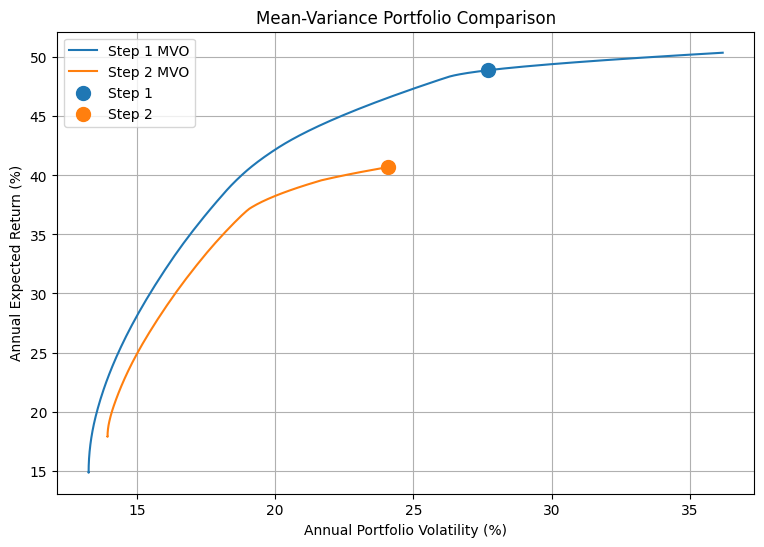

In [ ]:
## Step 3: efficient frontiers comparison
# samples using different gammas
gammas = np.logspace(-3, 5, 500)
def efficient_frontiers(upper_bound):
  bounds = [(0, upper_bound)] * n
  samples = []

  for gamma in gammas:
    ret = minimize(lambda w: 0.5 * gamma * (w @ cov @ w) - w @ mean, w0, method='SLSQP', constraints=constraints, bounds=bounds) # mean-variance
    if ret.success:
      samples.append((portfolio_volatility(ret.x) * 100, portfolio_return(ret.x) * 100))

  return np.array(sorted(samples))

frontier_step1 = efficient_frontiers(1)
frontier_step2 = efficient_frontiers(0.18)

# results
plt.figure(figsize=(9, 6))
plt.plot(frontier_step1[:, 0], frontier_step1[:, 1], label = 'Step 1 MVO')
plt.plot(frontier_step2[:, 0], frontier_step2[:, 1], label = 'Step 2 MVO')

# Mark our prevous solutions
for w, l in [(mvo.x, 'Step 1'), (mvo_new.x, 'Step 2')]:
  plt.scatter(portfolio_volatility(w) * 100, portfolio_return(w) * 100, label=l, s=100)

plt.xlabel("Annual Portfolio Volatility (%)")
plt.ylabel("Annual Expected Return (%)")
plt.title("Mean-Variance Portfolio Comparison")
plt.legend()
plt.grid(True)
plt.show()


Step 2 curve lies below step 1. That means the constrained one (maximum 18%) achieves a lower maximum expected annual return (about 40%), compared to the non-constrained one (at about 50%). In addition, the constrainted one reaches only at about 25% volatility, compared to at about 35% for the non-constrained one. This suggests that limiting individual asset weights (at 18%) forces us to spread our money across more stocks, i.e. diversify the portfolio, but it reduces the expected return.

In [ ]:
## Step 4: performance
# out-of-samples returns
w = pd.DataFrame({'Step 1': mvo.x, 'Step 2': mvo_new.x}, index=tickers)
portfolio_returns = returns_out_sample[tickers] @ w
cumulative_returns = (1 + portfolio_returns).cumprod()
rf = ff_out_sample['RF'].mean()
excess_returns = portfolio_returns - rf

performance = pd.DataFrame({
    'Cumulative Return (%)': (cumulative_returns.iloc[-1] - 1) * 100,
    'Sharpe Ratio': (excess_returns.mean() / excess_returns.std()) * np.sqrt(num_trading_days),
    'Max Drawdown (%)': (cumulative_returns / cumulative_returns.cummax().clip(lower=1) - 1).min() * 100
})

print("Out-of-sample Portfolio Performance:")
print(performance.round(2))

Out-of-sample Portfolio Performance:
        Cumulative Return (%)  Sharpe Ratio  Max Drawdown (%)
Step 1                  -1.29         -0.33            -13.52
Step 2                   7.00          1.30             -6.24


# Part 2

### Step 4: Factor Correlation Matrix Analysis

In [ ]:
import statsmodels.api as sm
from sklearn.linear_model import HuberRegressor
import pandas as pd
import numpy as np

# Factor Correlation Analysis
factors_in_sample = ff_in_sample[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']]
corr_matrix = factors_in_sample.corr()

print("=== Fama-French 5-Factor In-Sample Correlation Matrix ===")
print(corr_matrix.round(4))

# Compute Daily Excess Portfolio Returns for Step 2 Portfolio (Training Period)
# Convert Fama-French data index to datetime (using to_timestamp if it is a PeriodIndex)
ff_in_sample_dt = ff_in_sample.copy()
if isinstance(ff_in_sample_dt.index, pd.PeriodIndex):
    ff_in_sample_dt.index = ff_in_sample_dt.index.to_timestamp()
else:
    ff_in_sample_dt.index = pd.to_datetime(ff_in_sample_dt.index)

# Define w_step2 from the Step 2 Mean Variance weights computed earlier
w_step2 = weights_new['Mean Variance'].values

# Filter returns_in_sample to only include the 10 portfolio tickers before taking the dot product
p_ret_in_sample = pd.Series(np.dot(returns_in_sample[tickers].values, w_step2), index=pd.to_datetime(returns_in_sample.index))
p_excess_in_sample = p_ret_in_sample - ff_in_sample_dt['RF']

=== Fama-French 5-Factor In-Sample Correlation Matrix ===
        Mkt-RF     SMB     HML     RMW     CMA
Mkt-RF  1.0000  0.2115 -0.2552 -0.3841  0.0249
SMB     0.2115  1.0000  0.3924 -0.4007  0.1535
HML    -0.2552  0.3924  1.0000  0.1861  0.1050
RMW    -0.3841 -0.4007  0.1861  1.0000 -0.1104
CMA     0.0249  0.1535  0.1050 -0.1104  1.0000


### Step 5: OLS and Robust Model Regression Estimation

In [ ]:
factors_dt = ff_in_sample_dt[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']]
X_train = sm.add_constant(factors_dt)
y_train = p_excess_in_sample

# 1. OLS Regression with Newey-West (HAC) Standard Errors
ols_model = sm.OLS(y_train, X_train).fit(cov_type='HAC', cov_kwds={'maxlags': 5})

# 2. Huber Robust Regression Estimation
huber = HuberRegressor(epsilon=1.35, max_iter=1000)
huber.fit(factors_dt.values, y_train.values)
huber_coefs = [huber.intercept_] + list(huber.coef_)

# Align indices for OLS Series to match 'Alpha (Intercept)' instead of 'const'
ols_params = ols_model.params.rename(index={'const': 'Alpha (Intercept)'})
ols_bse = ols_model.bse.rename(index={'const': 'Alpha (Intercept)'})
ols_tvalues = ols_model.tvalues.rename(index={'const': 'Alpha (Intercept)'})
ols_pvalues = ols_model.pvalues.rename(index={'const': 'Alpha (Intercept)'})

# Summary Table of Factor Loadings
df_regression = pd.DataFrame({
    'OLS Coef': ols_params,
    'OLS HAC Std Err': ols_bse,
    'OLS t-Stat': ols_tvalues,
    'OLS p-Value': ols_pvalues,
    'Huber Coef': pd.Series(huber_coefs, index=['Alpha (Intercept)', 'Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA'])
})

print("\n=== Fama-French 5-Factor Regression Results (Step 2 Portfolio) ===")
print(df_regression.round(5))

print(f"\nOLS Model R-squared: {ols_model.rsquared:.4f}")
print(f"OLS Model Adjusted R-squared: {ols_model.rsquared_adj:.4f}")


=== Fama-French 5-Factor Regression Results (Step 2 Portfolio) ===
                   OLS Coef  OLS HAC Std Err  OLS t-Stat  OLS p-Value  \
Alpha (Intercept)   0.00038          0.00032     1.19062      0.23380   
Mkt-RF              1.30211          0.03617    35.99540      0.00000   
SMB                -0.09153          0.07197    -1.27179      0.20345   
HML                 0.17163          0.06774     2.53380      0.01128   
RMW                -0.13059          0.09442    -1.38303      0.16666   
CMA                -0.46608          0.09178    -5.07841      0.00000   

                   Huber Coef  
Alpha (Intercept)     0.00024  
Mkt-RF                1.27031  
SMB                  -0.06819  
HML                   0.16104  
RMW                  -0.11530  
CMA                  -0.38127  

OLS Model R-squared: 0.7767
OLS Model Adjusted R-squared: 0.7745


# George's work:
Friends, don't overwrite my report or make any modification to it, just have a look. I'll delete this "George's work" heading later once I complete my contribution.

# part 4: Black Litterman



## step 9

plan:

1. Get the market data; Historical returns, covariance matrix of assets in our portfolio and market capitilization weights to calculate $w_{\text{mkt}} $
2. Get Expected returns of the market: $ \pi = \delta\Sigma w_{mkt} $
3. write absolute or relative beliefs about returns: $ P\mu = Q $
4. Get the Bayesian posterior estimations: $ \mu_{BL},\quad\Sigma_{BL},\quad w_{BL} $
5. The idea is mean-variance optimization derived expected returns is unreliable in times of extreme market volatility and also because it is not flexible enough to incorporate our own beliefs about the market or assets we want to have in our portfolio and update it with supporting or adversarial information so, in blacklitterman we start with a simple prior belief that is consistent with how the market performs (our perception based on data we observed) and incorporate that belief into our model to select optimal weights to create good portfolio.


lets install yfinance quietly without showing any warning messages, the '-q' takes care of it.

In [1]:
# !pip -q install yfinance

In [2]:
## Basic data processing tools
import numpy as np
import pandas as pd

## our beloved yahoo finance
import yfinance as yf

## basic plotting tool
import matplotlib.pyplot as plt

## this is for minimizing negative sharpe ratio or variance of our portfolio
from scipy.optimize import minimize

## for accessing or creating files
from google.colab import files

## some input output operations, zipping, and http requests to get data from fama-french
import io
import zipfile
import requests


plan:

1. store all our tickers
2. set s&p 500 index GSPC as our benchmark, define start and end dates, trading days, etc...
3. I want to set the max_weight for the maximum proportion we can invest in any asset in our portfolio to be within 18% as it is one of the constraints mentioned.
4. No short selling is allowed as the weights are supposed to vary between 0 and 0.18 and never become negative.

$$ \sum_{i=1}^{10}w_i=1 $$
$$ 0\leq w_i\leq0.18 $$

In [3]:
TICKERS = [
    "TSLA", "WMT", "BAC", "GS", "LLY",
    "MRK", "GOOG", "META", "AAPL", "XOM"
]
BENCHMARK = "^GSPC"
START_DATE = "2023-08-31"
END_DATE = "2025-10-02"
TRADING_DAYS = 252
MAX_WEIGHT = 0.18

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


download the tickers and s&p 500 historical prices from yahoo finance from start date till end date.

In [4]:

download = yf.download(
    TICKERS + [BENCHMARK],
    start=START_DATE,
    end=END_DATE,
    auto_adjust=False,
    progress=False,
    actions=False
)



In [5]:
download.head(5)

Price       Adj Close                                                        \
Ticker           AAPL       BAC       GOOG         GS        LLY       META   
Date                                                                          
2023-08-31 185.362930 26.681417 136.061295 306.519379 542.899109 293.082947   
2023-09-01 186.931763 26.969915 135.516464 306.229370 545.749756 293.568298   
2023-09-05 187.168549 26.662800 135.427277 302.815491 546.807739 297.302521   
2023-09-06 180.469131 26.420835 134.099854 300.364807 548.531799 296.331787   
2023-09-07 175.190521 26.178869 134.922058 301.141144 561.541077 295.836548   

Price                                                 ...    Volume            \
Ticker           MRK       TSLA       WMT        XOM  ...       BAC      GOOG   
Date                                                  ...                       
2023-08-31 98.779655 258.079987 52.522732 100.754738  ...  37243000  28147900   
2023-09-01 99.559128 245.009995 52.186810 102.866066  ...  35228600  16671600   
2023-09-05 97.447235 256.489990 51.766903 102.875130  ...  46543600  17730200   
2023-09-06 96.522697 251.919998 52.154507 103.763161  ...  45022600  15814300   
2023-09-07 97.836967 251.490005 52.800503 103.255699  ...  35023600  16976000   

Price                                                                 \
Ticker           GS      LLY      META      MRK       TSLA       WMT   
Date                                                                   
2023-08-31  1271100  3043400  17229900  9212000  108861700  19582800   
2023-09-01  1201400  2030800  12842300  4941300  132541600  12553500   
2023-09-05  1846000  2257200  14956000  6379900  129469600  15209400   
2023-09-06  2120800  2424300  15418100  7926100  116959800  14594700   
2023-09-07  1471100  3707100  33748700  8532600  115312900  19120800   

Price                             
Ticker           XOM       ^GSPC  
Date                              
2023-08-31  17479800  3946360000  
2023-09-01  14843500  3246260000  
2023-09-05  18304000  3526250000  
2023-09-06  13325500  3418850000  
2023-09-07  13248500  3763760000  

[5 rows x 66 columns]

Even though we see the adjusted close column is present in our download DataFrame, we want to explicitly check it and raise error just as a convention.

In [6]:
if "Adj Close" not in download.columns.get_level_values(0):
    raise ValueError("Adjusted Close field was not returned.")

* take a copy of all assets' ajusted close prices.
* set the index to dates
* sort the index in ascending order

In [7]:
prices_all = download["Adj Close"].copy()
prices_all.index = pd.to_datetime(prices_all.index)
prices_all = prices_all.sort_index()

asset_prices = prices_all[TICKERS]
benchmark_prices = prices_all[BENCHMARK].rename("SP500")



get returns for all assets and benchmark.

In [8]:
# Daily simple returns
asset_returns_all = asset_prices.pct_change(fill_method=None)
benchmark_returns_all = benchmark_prices.pct_change(fill_method=None)


by default, pct_change method has the tendency to forward fill missing NaN values with previous return, we don't want that to happen so, I explicitly set it to None.

Using only the dates for Black Litterman parameter estimations

In [9]:

asset_returns = asset_returns_all.loc[
    "2023-09-01":"2025-09-30"
]
benchmark_returns = benchmark_returns_all.loc[
    "2023-09-01":"2025-09-30"
]


All ten stocks and benchmark must be observed on the same dates

In [10]:
combined = pd.concat(
    [asset_returns, benchmark_returns], axis=1
).dropna()

asset_returns = combined[TICKERS]
benchmark_returns = combined["SP500"]


In [11]:
len(combined)

521

we have 521 observations in our combined dataframe.

In [12]:
# our starting is going to be
combined.index.min()

Timestamp('2023-09-01 00:00:00')

In [13]:
# ending date in the combined dataframe
combined.index.max()

Timestamp('2025-09-30 00:00:00')

In [14]:
# calculate the missing values(if any)
combined.isna().sum().sum()

np.int64(0)

lets display our beautiful dataFrame

In [15]:
# lets display our beautiful combined dataFrame
display(combined.head())

,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,SP500
Date,,,,,,,,,,,
2023-09-01,-0.050643,-0.006396,0.010813,-0.000946,0.005251,0.007891,-0.004004,0.001656,0.008464,0.020955,0.001799
2023-09-05,0.046855,-0.008046,-0.011387,-0.011148,0.001939,-0.021212,-0.000658,0.012720,0.001267,0.000088,-0.004194
2023-09-06,-0.017817,0.007487,-0.009075,-0.008093,0.003153,-0.009488,-0.009802,-0.003265,-0.035793,0.008632,-0.006972
2023-09-07,-0.001707,0.012386,-0.009158,0.002585,0.023717,0.013616,0.006131,-0.001671,-0.029249,-0.004891,-0.003211
2023-09-08,-0.011889,0.001835,0.008177,0.011057,0.023080,0.010284,0.007342,-0.002611,0.003492,0.014568,0.001427


next up we are going to load the market cap weights, this is the one input we must source from some sec.gov archives so,lets Obtain the S&P 500 index weights of the ten stocks from here. [The site address is here:](https://www.sec.gov/Archives/edgar/data/884394/000119312525297563/d18808dn30d.htm)



In [16]:
market_weights_df = pd.DataFrame({
    "ticker": [
        "TSLA", "WMT", "BAC", "GS", "LLY",
        "MRK", "GOOG", "META", "AAPL", "XOM"
    ],
    "weight": [
        0.02187476,
        0.00792861,
        0.00616164,
        0.00422510,
        0.01063242,
        0.00367386,
        0.04472378,
        0.02792067,
        0.06623971,
        0.00842514
    ]
})

market_weights_df.to_csv(
    "sp500_weights.csv", index=False
)

# files.download("sp500_weights.csv")


verify the residual portfolio weight.

Blacklitterman requires a market portfolio weights and its corresponding covariance matrix but we can't get it with weights of just 10 assets so to get the total market portfolio weight we take the weights of those 10 assets we have and subtract 1 from this weight to get the rest of the portfolio weight.

process:

1. Access the weight column from market_weights_df
2. to get the rest of the companies' weights from s&p 500 apart from these 10 stocks in our portfolio do:  1 - weights_of_ten_stocks_in_our_portfolio.
3. combine the weight of 10 stocks in our portfolio with the weight of rest of the companies in s&p 500.

In [17]:

w10 = market_weights_df.set_index("ticker")["weight"]

w_rest = 1 - w10.sum()

market_weights = pd.concat([
    w10,
    pd.Series({"REST_SP500": w_rest})
])

display(market_weights.to_frame("market_weight"))



,market_weight
TSLA,0.021875
WMT,0.007929
BAC,0.006162
GS,0.004225
LLY,0.010632
MRK,0.003674
GOOG,0.044724
META,0.027921
AAPL,0.066240
XOM,0.008425


Check whether all eleven weights sum to approximately 1 or 100%

In [18]:
assert abs(market_weights.sum() - 1) < 1e-8

yes it does!

In [19]:
print(f"Total market weight: {market_weights.sum():.4%}")
print(f"Residual market weight: {w_rest:.4%}")

Total market weight: 100.0000%
Residual market weight: 79.8194%


We start with ten stocks representing approximately 20.18% of the S&P 500 and construct an eleventh synthetic asset representing the remaining 79.82%

Now we don't have the actual:

* we have to calculate this residual return by multiplying each stock's returns in our portfolio with their corresponding weights and find how much it deviates from the market returns.

$$ r_{\text{rest},t} =
\frac{r_{\text{mkt},t}-\sum_{i=1}^{10}w_i r_{i,t}}
{w_{\text{rest}}} $$

* $ r_{\text{mkt},t } $ is market returns, $ w_i $ is the weight of the i-th asset in our portfolio, $ r_{i,t} $ is the return of our i-th asset, $ w_{\text{rest} } $ is the remaining weight.

* combine the ten stocks return column with the residual return column.

* Then find the maximum error: $$
\text{Maximum Error}
=\max_t |r_{\text{reconstructed},t}-r_{\text{benchmark},t}| $$

* Checks whether the maximum reconstruction error is smaller than $ 10^{-10} $.

In [20]:

# Align stock returns with the benchmark on identical dates.
r10 = asset_returns.copy()
r_mkt = benchmark_returns.copy()

# Synthetic residual return:
# r_SP500 = sum(w_i * r_i) + w_rest * r_rest
r_rest = (
    r_mkt - r10.mul(w10, axis="columns").sum(axis=1)
) / w_rest

r_rest.name = "REST_SP500"

returns_11 = pd.concat([r10, r_rest], axis=1)

market_tickers = TICKERS + ["REST_SP500"]
returns_11 = returns_11[market_tickers].dropna()

# Verify the reconstructed index return.
reconstructed_market = returns_11 @ market_weights
benchmark_aligned = r_mkt.loc[returns_11.index]

max_error = (
    reconstructed_market - benchmark_aligned
).abs().max()

print("Maximum reconstruction error:", max_error)
assert max_error < 1e-10

display(returns_11.head())


Maximum reconstruction error: 3.469446951953614e-18


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,REST_SP500
Date,,,,,,,,,,,
2023-09-01,-0.050643,-0.006396,0.010813,-0.000946,0.005251,0.007891,-0.004004,0.001656,0.008464,0.020955,0.002764
2023-09-05,0.046855,-0.008046,-0.011387,-0.011148,0.001939,-0.021212,-0.000658,0.012720,0.001267,0.000088,-0.006754
2023-09-06,-0.017817,0.007487,-0.009075,-0.008093,0.003153,-0.009488,-0.009802,-0.003265,-0.035793,0.008632,-0.004663
2023-09-07,-0.001707,0.012386,-0.009158,0.002585,0.023717,0.013616,0.006131,-0.001671,-0.029249,-0.004891,-0.002227
2023-09-08,-0.011889,0.001835,0.008177,0.011057,0.023080,0.010284,0.007342,-0.002611,0.003492,0.014568,0.000855


Everything appears good!

we got our market weight.
Lets now calculate our covariance matrix to calculate expected return of the market: $ \pi = \delta\Sigma w_{mkt} $

In [21]:

# Annualized covariance matrix for all 11 assets.
cov_daily_11 = returns_11.cov()
cov_annual_11 = TRADING_DAYS * cov_daily_11



In [22]:
TRADING_DAYS

252

In [23]:
# Annualized benchmark return series and variance.
market_return_daily = benchmark_aligned
market_variance_annual = (
    market_return_daily.var(ddof=1) * TRADING_DAYS
)


In [24]:
cov_annual_11.shape

(11, 11)

In [25]:
market_variance_annual

0.02495483670314396

we have to make sure that our covariance matrix is symmetric.

In [26]:
assert np.allclose(
    cov_annual_11.values,
    cov_annual_11.values.T,
    atol=1e-10
)

In [27]:
eigenvalues = np.linalg.eigvalsh(cov_annual_11.values)
print("Minimum covariance eigenvalue:", eigenvalues.min())

assert eigenvalues.min() > -1e-8


Minimum covariance eigenvalue: 0.005220042627082764


Also it must be positive definite; $ \forall x \in \text{eigenvalues}  > 0. $. if any of our eigen values is negative, then we must see what's wrong with our data analysis, fortunately they are all positive as our result shows above.

### Estimate implied equilibrium returns $ \pi = \delta\Sigma w_{mkt} $:

As per lesson notes, the official French Data Library provides the daily five-factor file and includes the risk-free rate, RF. so, why not use it?

The Fama-French data files contain a few lines of introductory text/notes at the very top before the column headers actually start. so we want to skip the first three rows of our downloaded file.

In [28]:
ff_url = (
    "https://mba.tuck.dartmouth.edu/pages/faculty/"
    "ken.french/ftp/"
    "F-F_Research_Data_5_Factors_2x3_daily_CSV.zip"
)

response = requests.get(ff_url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_name = next(
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    )
    ff_raw = pd.read_csv(
        z.open(csv_name),
        skiprows=3
    )

plan:
* get the date column seperately do these tests and modifications
* using a Regular Expression (r"\d{8}"), we want to check every row in the date column to see if it contains exactly 8 consecutive digits ( 4 digits for the year, 2 for the month, 2 for the day).
* set it as the index.

In [29]:
# The first column is the date; remove footer and blank rows.
date_col = ff_raw.columns[0]
ff_raw[date_col] = (
    ff_raw[date_col].astype(str).str.strip()
)

ff_raw = ff_raw[
    ff_raw[date_col].str.fullmatch(r"\d{8}", na=False)
].copy()

ff_raw[date_col] = pd.to_datetime(
    ff_raw[date_col], format="%Y%m%d"
)

ff_raw = ff_raw.set_index(date_col)
ff_raw.index.name = "Date"


further modifications:
* Fama-French data columns often load as text strings due to messy formatting. we want to convert and force every single column in the table into floats or integers. If it encounters any stray text it can't convert, "coerce" that specific cell into an empty value (NaN) instead of crashing.

* The five factors we are looking for from Fama french dataset are: Market Risk Premium, Size, Value, Profitability, Investment, and the Risk-Free Rate.

* if any factor is missing, flag it as such.

* get the data of these factors between our start and end dates.

In [30]:
# All factor values in the French file are percentages.
ff = ff_raw.apply(pd.to_numeric, errors="coerce") / 100

required = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"]

"""
This compares your required list against the actual columns in the downloaded file.
It flags any names that are missing.
"""

missing = set(required) - set(ff.columns)

if missing:
    raise ValueError(f"Missing factor columns: {missing}")

ff = ff[required].loc["2023-09-01":"2025-09-30"].dropna()

get the risk free data.

In [31]:
# Align RF to the returns used in the market calculation.
rf_daily = ff["RF"].reindex(returns_11.index)

if rf_daily.isna().any():
    raise ValueError("Risk-free data does not align with returns.")

print("Factor observations:", len(ff))
display(ff.head())


Factor observations: 521


,Mkt-RF,SMB,HML,RMW,CMA,RF
Date,,,,,,
2023-09-01,0.002600,0.008500,0.005800,0.000000,-0.002200,0.000200
2023-09-05,-0.005400,-0.015700,-0.008700,-0.003000,-0.004800,0.000200
2023-09-06,-0.007100,0.000100,-0.001800,-0.004500,0.001000,0.000200
2023-09-07,-0.004000,-0.006900,0.000200,-0.001900,0.000200,0.000200
2023-09-08,0.001200,-0.005100,0.004000,0.002900,0.000100,0.000200


calculate $ \delta $:

which is,
$ \delta  = \frac{\text{sharpe}}{\text{market variance}} $



In [32]:
# Annualized arithmetic mean of the market's daily excess return.
market_excess_daily = (
    market_return_daily - rf_daily
)

market_excess_mean_annual = (
    market_excess_daily.mean() * TRADING_DAYS
)

# this step is totally unnecessary but I should highlight what is sharpe here
sharpe = market_excess_mean_annual

delta = (
    sharpe / market_variance_annual
)

w_mkt = market_weights.reindex(market_tickers).values

In [33]:
delta, w_mkt

(np.float64(6.128342851076704),
 array([0.021875, 0.007929, 0.006162, 0.004225, 0.010632, 0.003674,
        0.044724, 0.027921, 0.06624 , 0.008425, 0.798194]))

finally calculate $ \pi $ now:

In [34]:
# Reverse-optimized equilibrium excess returns.
pi = delta * cov_annual_11.values @ w_mkt
pi = pd.Series(pi, index=market_tickers, name="pi")


print(f"Annual market excess return: {market_excess_mean_annual:.4%}")
print(f"Annual market variance: {market_variance_annual:.6f}")
print(f"Risk aversion delta: {delta:.6f}")


display(pi.to_frame("implied_excess_return or pi is:"))

Annual market excess return: 15.2932%
Annual market variance: 0.024955
Risk aversion delta: 6.128343


,implied_excess_return or pi is:
TSLA,0.355399
WMT,0.082396
BAC,0.151381
GS,0.201120
LLY,0.119201
MRK,0.048234
GOOG,0.171686
META,0.225165
AAPL,0.183662
XOM,0.063901


our delta needs to be positive and finite

In [35]:
assert np.isfinite(delta) and delta > 0
assert np.isfinite(pi.values).all()

### Incorporate P,Q, $\Omega $:
Investor's view

This is the P,Q, Omega of our formula.

I believe or if the investor beliefs that
1. GOOG outperforms META by 2 percentage points annually.
2. XOM has an expected annual excess return of 6%.


Actually GooG outperformed META by a larger percentage (like 8-10%) in the past 10 years so, I'm being conservative here and for XOM in the past 5 years its actual excess return is well over 12% given a risk-free rate of 4% so, my 6% is conservative here too.

In order to incorporate this into our model we have to build pick matrix (p) and excess return vector (Q) and how much we think that excess return would vary ($\omega$). Let's build it.

In [36]:

# Number of daily observations used to estimate Sigma.
T = len(returns_11)
tau = 1.0 / T

tau

0.0019193857965451055

In [37]:
T

521

In [38]:
asset_index = {ticker: i for i, ticker in enumerate(market_tickers)}

asset_index

{'TSLA': 0,
 'WMT': 1,
 'BAC': 2,
 'GS': 3,
 'LLY': 4,
 'MRK': 5,
 'GOOG': 6,
 'META': 7,
 'AAPL': 8,
 'XOM': 9,
 'REST_SP500': 10}

now that we have indexed our assets from 0 to 10 we have to build our gloriously gleaming pick matrix (p)

since google we believe would outperform Meta, we have to go long on google and short on Meta, so first we have to put 1 in the place of google for going long in it, and -1 in the index of Meta for shorting it in the first row(first row is our first belief, and second row is our second belief, each belief will have its unique row in the pick matrix: kundi beliefs will have Kundi rows, Love beliefs will have Love rows, K beliefs will have K rows)

In [39]:
# Two illustrative views:
# 1. GOOG outperforms META by 2 percentage points annually.
# 2. XOM has an expected annual excess return of 6%.
P = np.zeros((2, len(market_tickers)))

P[0, asset_index["GOOG"]] = 1.0
P[0, asset_index["META"]] = -1.0

P[1, asset_index["XOM"]] = 1.0

P

array([[ 0.,  0.,  0.,  0.,  0.,  0.,  1., -1.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.]])

Now Q vector

This will have our excess returns; google will have outperformed by **2%** and XOM will have an annual excess return of **6%**.

In [40]:
Q = np.array([0.02, 0.06])

Q

array([0.02, 0.06])

now $\omega $ which is just $\tau P \Sigma^{\text{11 assets}} P^T $

In [41]:
# Diagonal view uncertainty.
view_covariance = P @ cov_annual_11.values @ P.T
omega = np.diag(tau * np.diag(view_covariance))
omega

array([[0.000225, 0.      ],
       [0.      , 0.000094]])

here another sneaked in assumption is our views are independent of each other reflected by our zero correlation but in reality things can be correlated or inverse correlated or whatever.

Time for beautiful displays and printouts

In [42]:
print("tau:", tau)
print("P shape:", P.shape)
print("Q shape:", Q.shape)
print("Omega shape:", omega.shape)

print("\nP:")
display(pd.DataFrame(P, columns=market_tickers,
                     index=["GOOG_vs_META", "XOM_absolute"]))

print("\nQ:")
display(pd.Series(Q, index=["GOOG_vs_META", "XOM_absolute"],
                  name="annual_view"))

print("\nOmega:")
display(pd.DataFrame(omega,
                     index=["GOOG_vs_META", "XOM_absolute"],
                     columns=["GOOG_vs_META", "XOM_absolute"]))


# we have to make sure that our omega has only positive values in its diagonal positions.
assert np.all(np.diag(omega) > 0)


tau: 0.0019193857965451055
P shape: (2, 11)
Q shape: (2,)
Omega shape: (2, 2)

P:


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,REST_SP500
GOOG_vs_META,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,-1.000000,0.000000,0.000000,0.000000
XOM_absolute,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000



Q:


,annual_view
GOOG_vs_META,0.020000
XOM_absolute,0.060000



Omega:


,GOOG_vs_META,XOM_absolute
GOOG_vs_META,0.000225,0.000000
XOM_absolute,0.000000,0.000094


### calculate Posterior returns and Variance:

Now, we have to calculate this posterior mean:
$$ \mu_{BL}=\pi+\tau\Sigma P^\top
(\Omega+\tau P\Sigma P^\top)^{-1}(Q-P\pi) $$

and Posterior Variance:

$$ \Sigma_{BL}=\Sigma+
\left[(\tau\Sigma)^{-1}+P^\top\Omega^{-1}P\right]^{-1} $$

I think we have all the components needed to perform the calculation.


In [43]:
Sigma = cov_annual_11.values
pi_vec = pi.values

# Posterior expected excess returns.
middle = omega + tau * P @ Sigma @ P.T

mu_bl = (
    pi_vec
    + tau * Sigma @ P.T
    @ np.linalg.solve(middle, Q - P @ pi_vec)
)

mu_bl = pd.Series(
    mu_bl, index=market_tickers, name="mu_bl"
)


In [44]:
mu_bl

,mu_bl
TSLA,0.353270
WMT,0.079529
BAC,0.148316
GS,0.197428
LLY,0.112225
MRK,0.047385
GOOG,0.183124
META,0.199820
AAPL,0.182207
XOM,0.061512


In [45]:
# Posterior covariance of returns, using a numerically stable solve.
prior_precision = np.linalg.solve(tau * Sigma, np.eye(len(Sigma)))
view_precision = P.T @ np.linalg.solve(omega, P)

posterior_uncertainty = np.linalg.solve(
    prior_precision + view_precision,
    np.eye(len(Sigma))
)

cov_bl = Sigma + posterior_uncertainty
cov_bl = (cov_bl + cov_bl.T) / 2

cov_bl = pd.DataFrame(
    cov_bl, index=market_tickers, columns=market_tickers
)
cov_bl

,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,REST_SP500
TSLA,0.396482,0.034620,0.056671,0.077202,0.030511,0.006779,0.071435,0.076956,0.077126,0.013101,0.047064
WMT,0.034620,0.044756,0.014210,0.016713,0.014365,0.005316,0.010850,0.019684,0.017723,0.003488,0.012264
BAC,0.056671,0.014210,0.065610,0.056175,0.013638,0.007908,0.019099,0.026837,0.024359,0.021020,0.024032
GS,0.077202,0.016713,0.056175,0.080324,0.020501,0.008150,0.029947,0.039655,0.031946,0.021419,0.031795
LLY,0.030511,0.014365,0.013638,0.020501,0.124439,0.026946,0.013387,0.035276,0.016221,0.004527,0.018060
MRK,0.006779,0.005316,0.007908,0.008150,0.026946,0.058439,0.001550,0.003622,0.010439,0.006549,0.007758
GOOG,0.071435,0.010850,0.019099,0.029947,0.013387,0.001550,0.087554,0.050591,0.037416,0.003430,0.022794
META,0.076956,0.019684,0.026837,0.039655,0.035276,0.003622,0.050591,0.131124,0.040885,0.006236,0.032022
AAPL,0.077126,0.017723,0.024359,0.031946,0.016221,0.010439,0.037416,0.040885,0.077048,0.012052,0.024656
XOM,0.013101,0.003488,0.021020,0.021419,0.004527,0.006549,0.003430,0.006236,0.012052,0.049026,0.010388


Now let's compare our posterior results with market implied excess returns($\pi$)

In [46]:



results = pd.DataFrame({
    "market_implied_excess_return": pi,
    "BL_excess_return": mu_bl,
    "change": mu_bl - pi
})

display(results.style.format("{:.4%}"))
display(cov_bl.round(6))



,market_implied_excess_return,BL_excess_return,change
TSLA,35.5399%,35.3270%,-0.2129%
WMT,8.2396%,7.9529%,-0.2867%
BAC,15.1381%,14.8316%,-0.3065%
GS,20.1120%,19.7428%,-0.3693%
LLY,11.9201%,11.2225%,-0.6976%
MRK,4.8234%,4.7385%,-0.0849%
GOOG,17.1686%,18.3124%,1.1438%
META,22.5165%,19.9820%,-2.5344%
AAPL,18.3662%,18.2207%,-0.1455%
XOM,6.3901%,6.1512%,-0.2389%


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,REST_SP500
TSLA,0.396482,0.034620,0.056671,0.077202,0.030511,0.006779,0.071435,0.076956,0.077126,0.013101,0.047064
WMT,0.034620,0.044756,0.014210,0.016713,0.014365,0.005316,0.010850,0.019684,0.017723,0.003488,0.012264
BAC,0.056671,0.014210,0.065610,0.056175,0.013638,0.007908,0.019099,0.026837,0.024359,0.021020,0.024032
GS,0.077202,0.016713,0.056175,0.080324,0.020501,0.008150,0.029947,0.039655,0.031946,0.021419,0.031795
LLY,0.030511,0.014365,0.013638,0.020501,0.124439,0.026946,0.013387,0.035276,0.016221,0.004527,0.018060
MRK,0.006779,0.005316,0.007908,0.008150,0.026946,0.058439,0.001550,0.003622,0.010439,0.006549,0.007758
GOOG,0.071435,0.010850,0.019099,0.029947,0.013387,0.001550,0.087554,0.050591,0.037416,0.003430,0.022794
META,0.076956,0.019684,0.026837,0.039655,0.035276,0.003622,0.050591,0.131124,0.040885,0.006236,0.032022
AAPL,0.077126,0.017723,0.024359,0.031946,0.016221,0.010439,0.037416,0.040885,0.077048,0.012052,0.024656
XOM,0.013101,0.003488,0.021020,0.021419,0.004527,0.006549,0.003430,0.006236,0.012052,0.049026,0.010388


lets see how much our view(that P,Q,omega) has influenced the posterior result we observe here

In [47]:
# Compare the specified view with the prior and posterior.
prior_spread = pi["GOOG"] - pi["META"]
posterior_spread = mu_bl["GOOG"] - mu_bl["META"]

print(f"Specified view:       {Q[0]:.4%}")
print(f"Prior GOOG-META:      {prior_spread:.4%}")
print(f"Posterior GOOG-META:  {posterior_spread:.4%}")

Specified view:       2.0000%
Prior GOOG-META:      -5.3479%
Posterior GOOG-META:  -1.6696%


Before applying the view, the market-implied return difference was:
$$ 17.1686\%-22.5165\%=-5.3479\% $$

After applying the view:
$$ 18.3124\%-19.9820\%=-1.6696\% $$

The relative return difference moved upward by:
$$ -1.6696\%-(-5.3479\%)=3.6783\text{ percentage points} $$

our specified view was a 2-percentage-point outperformance, whereas the posterior still implies that META has a higher expected excess return than GOOG.

---

We obtained a negative posterior spread but, it moved in the positive direction, toward my view.



| Stage                         | GOOG − META | Interpretation                                      |
| ----------------------------- | ----------- | --------------------------------------------------- |
| Initial market-implied spread | −5.3479%    | META has the higher expected excess return.         |
| our specified view           | +2.0000%    | GOOG should outperform META by 2 percentage points. |
| BL posterior spread           | −1.6696%    | META still has the higher expected excess return.   |

The model moved the spread by:

\\[ -1.6696\\%-(-5.3479\\%)=+3.6783\text{ pp} \\]

So the posterior moved against the initial market-implied relative expectation, but it did not reverse the ranking.



- Prior belief: META outperforms GOOG by 5.35 percentage points.
- Investor view: GOOG outperforms META by 2 percentage points.
- Posterior belief: META still outperforms GOOG, but only by 1.67 percentage points.



If we want the posterior spread to become positive, we need to increase confidence in your GOOG-versus-META view by reducing its uncertainty in $\Omega $. That would pull the posterior closer to +2%.

Black–Litterman determines how much the prior should change based on the confidence assigned to each view. Okay let's try to optimize now to get the proportion or percentage of money we have to invest in each of ten assets based on this posterior result.


first lets make sure Sigma matrix is symmetric. Eigen values are all non negative.

In [48]:
# Check whether the covariance matrix is symmetric.
print("Symmetric:", np.allclose(Sigma, Sigma.T))

# Check whether all eigenvalues are non-negative.
eigenvalues = np.linalg.eigvalsh(Sigma)

print("Minimum eigenvalue:", eigenvalues.min())

# Calculate annualized volatility.
annual_volatility = np.sqrt(np.diag(Sigma))

volatility_summary = pd.DataFrame({
    "Asset": market_tickers,
    "Annualized Volatility": annual_volatility
})

display(volatility_summary)

Symmetric: True
Minimum eigenvalue: 0.005220042627082764


,Asset,Annualized Volatility
0,TSLA,0.629067
1,WMT,0.211355
2,BAC,0.255917
3,GS,0.283160
4,LLY,0.352426
5,MRK,0.241511
6,GOOG,0.295631
7,META,0.361837
8,AAPL,0.277315
9,XOM,0.221311


Lets make some constraints to compare this against Lee's Part 1 results.

1.  long-only weights that sum to 1
2. We have a maximum weight of 18%.

We will solve the constrained optimization and our objective is mean–variance utility:
$$ \max_w\quad
w^\top\mu_{BL}-\frac{\delta}{2}w^\top\Sigma_{BL}w $$

subject to:
 $$ \sum_i w_i=1,\qquad 0\leq w_i\leq0.18 $$


In [49]:
mu_bl_10 = mu_bl.loc[TICKERS].values
cov_bl_10 = cov_bl.loc[TICKERS, TICKERS].values

def optimize_portfolio(mu, cov, risk_aversion,
                       max_weight=None):
    n = len(mu)

    if max_weight is not None and n * max_weight < 1:
        raise ValueError("Maximum weight constraint is infeasible.")

    bounds = (
        [(0.0, max_weight)] * n
        if max_weight is not None
        else [(0.0, 1.0)] * n
    )

    x0 = np.repeat(1 / n, n)

    def objective(w):
        return -(
            w @ mu
            - 0.5 * risk_aversion * (w @ cov @ w)
        )

    result = minimize(
        objective,
        x0=x0,
        method="SLSQP",
        bounds=bounds,
        constraints=[{
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1.0
        }],
        options={"maxiter": 5000, "ftol": 1e-12}
    )

    if not result.success:
        raise RuntimeError(result.message)

    if not np.isclose(result.x.sum(), 1.0, atol=1e-6):
        raise AssertionError("Weights do not sum to 1.")

    return pd.Series(result.x, index=TICKERS)

weights_bl = optimize_portfolio(
    mu_bl_10,
    cov_bl_10,
    delta,
    max_weight=MAX_WEIGHT
)

display(weights_bl.sort_values(ascending=False).to_frame("BL_weight"))

print("Sum of weights:", weights_bl.sum())
print("Maximum weight:", weights_bl.max())

assert (weights_bl >= -1e-8).all()
assert (weights_bl <= MAX_WEIGHT + 1e-6).all()


,BL_weight
GOOG,0.180000
GS,0.153512
AAPL,0.147284
WMT,0.126345
XOM,0.106734
MRK,0.089784
BAC,0.069659
LLY,0.051562
META,0.049647
TSLA,0.025473


Sum of weights: 1.0
Maximum weight: 0.18


### Comparing with mean-variance portfolio weights:

We can compare the two portfolio one created by sing chun Lee and one by me(George), the thing to be mindful of is both contain the same ten stocks, both are long-only, and both satisfy the 18% maximum-weight constraint, I made sure of that just to make this comparision. Now lets see how the two optimization methods allocate capital.




Weights are percentages of total portfolio capital. Difference = Black–Litterman minus Mean–Variance.

| Asset | Mean–Variance | Black–Litterman | Difference |
| ----- | ------------- | --------------- | ---------- |
| TSLA  | 18.00%        | 2.55%           | -15.45 pp  |
| WMT   | 18.00%        | 12.63%          | -5.37 pp   |
| BAC   | 13.96%        | 6.97%           | -6.99 pp   |
| GS    | 18.00%        | 15.35%          | -2.65 pp   |
| LLY   | 0.00%         | 5.16%           | +5.16 pp   |
| MRK   | 0.00%         | 8.98%           | +8.98 pp   |
| GOOG  | 14.04%        | 18.00%          | +3.96 pp   |
| META  | 18.00%        | 4.96%           | -13.04 pp  |
| AAPL  | 0.00%         | 14.73%          | +14.73 pp  |
| XOM   | 0.00%         | 10.67%          | +10.67 pp  |
| Total | 100.00%       | 100.00%         | 0.00 pp    |

The observations I can make out from this result is
A. Black–Litterman substantially reduced TSLA and META exposure.

- TSLA fell from 18% to 2.55%.
- META fell from 18% to 4.96%.

Together, they went from 36% of the mean–variance portfolio to approximately 7.51% of the Black–Litterman portfolio.

B. Black–Litterman introduced exposure to all ten assets.

Lee's portfolio allocated zero capital to LLY, MRK, AAPL, and XOM.

My BL portfolio allocated capital to all four:

- AAPL: 14.73%
- XOM: 10.67%
- MRK: 8.98%
- LLY: 5.16%

C. GOOG peaked the maximum allocation in both portfolios' comparison.

GOOG increased from 14.04% to 18%, reaching your 18% maximum-weight constraint. I think my positive GOOG-versus-META view does the doing here.





### Test A: no views should leave the prior unchanged

If no views are supplied, the posterior mean should equal the implied equilibrium returns.

In [50]:

mu_no_views = pi.copy()

assert np.allclose(mu_no_views.values, pi.values)
print("PASS: no-view posterior mean equals equilibrium prior.")


PASS: no-view posterior mean equals equilibrium prior.


### Test B: stronger views should produce a larger update

We are going to keep the views unchanged but reduce $ \Omega $ , so that we will show higher confidence in our views and lets see how our posterior mean changes

In [51]:

def posterior_mean(pi, Sigma, P, Q, tau, omega):
    middle = omega + tau * P @ Sigma @ P.T
    return pi + (
        tau * Sigma @ P.T
        @ np.linalg.solve(middle, Q - P @ pi)
    )

mu_weak = posterior_mean(
    pi_vec, Sigma, P, Q, tau, omega * 10
)

mu_strong = posterior_mean(
    pi_vec, Sigma, P, Q, tau, omega * 0.1
)

print("Weak-view adjustment:")
display(pd.Series(mu_weak - pi_vec, index=market_tickers))

print("Strong-view adjustment:")
display(pd.Series(mu_strong - pi_vec, index=market_tickers))


Weak-view adjustment:


,0
TSLA,-0.000405
WMT,-0.000526
BAC,-0.000586
GS,-0.000700
LLY,-0.001275
MRK,-0.000163
GOOG,0.002077
META,-0.004621
AAPL,-0.000281
XOM,-0.000500


Strong-view adjustment:


,0
TSLA,-0.003695
WMT,-0.005163
BAC,-0.005292
GS,-0.006427
LLY,-0.012618
MRK,-0.001456
GOOG,0.020833
META,-0.045977
AAPL,-0.002485
XOM,-0.003691


### Test C: lets verify our relative view

In [52]:

prior_spread = pi["GOOG"] - pi["META"]
posterior_spread = mu_bl["GOOG"] - mu_bl["META"]

print(f"Prior GOOG-META spread: {prior_spread:.2%}")
print(f"View target: {Q[0]:.2%}")
print(f"Posterior GOOG-META spread: {posterior_spread:.2%}")


Prior GOOG-META spread: -5.35%
View target: 2.00%
Posterior GOOG-META spread: -1.67%


The posterior spread rallies toward the 2% view.

### Test D: check the constrained portfolio

In [53]:

def validate_weights(weights, max_weight=0.18):
    return {
        "sum_to_one": np.isclose(weights.sum(), 1.0, atol=1e-6),
        "no_short_positions": weights.min() >= -1e-6,
        "respects_cap": weights.max() <= max_weight + 1e-6
    }

print(validate_weights(weights_bl))
assert all(validate_weights(weights_bl).values())


{'sum_to_one': np.True_, 'no_short_positions': True, 'respects_cap': True}


All constraints are satisfied. I don't know what more to say/test about it. what about sensitivity to sample size or $\tau $?

### Test E:  sensitivity to $ \tau $

In [54]:

sensitivity_rows = []

for tau_test in [0.001, 0.005, 1 / T, 0.05, 0.10]:
    mu_test = posterior_mean(
        pi_vec, Sigma, P, Q, tau_test, omega
    )

    w_test = optimize_portfolio(
        mu_test[:10],
        cov_bl_10,
        delta,
        max_weight=MAX_WEIGHT
    )

    sensitivity_rows.append({
        "tau": tau_test,
        "mean_abs_return_change": np.mean(
            np.abs(mu_test - pi_vec)
        ),
        "largest_weight": w_test.max(),
        "weight_change_from_base": (
            w_test - weights_bl
        ).abs().max()
    })

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)


,tau,mean_abs_return_change,largest_weight,weight_change_from_base
0,0.001000,0.003975,0.164277,0.015891
1,0.005000,0.008253,0.180000,0.016569
2,0.001919,0.005764,0.180000,0.000000
3,0.050000,0.010888,0.180000,0.034497
4,0.100000,0.011085,0.180000,0.035851


* Increasing $ \tau $  increases the influence of views.
* The average absolute return adjustment increases from 0.3975% at $ \tau=0.001 $ to 1.1085% at $ \tau=0.10\ $, surprise! surprise! (atleast to me, I didn't it would increase it like that).
* so not only investor view affects the posterior mean returns but also the sample size.

* Portfolio weights do not change proportionally, The largest weight reaches 18% for most tests caressing our maximum weight constraint like it wants to escape that bound as $\tau $ changes.




# Part 3: Simulation part

## step 7

 we have to simulate many times and find the number of times we have to run the simulation to get portfolio weights that would closely match those weights obtained by hard coded numerical optimization.

The conditions to meet are:
1. we have to select 5 assets out of the 10 given.
2. weights have to sum to 1.
3. There are no short sales.

In [55]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

1. select five assets. I'm going to select Tesla, Walmart, Google, Meta, Bank of America.
2. get their daily returns
3. get their annualized mean returns.
4. calculate annualized covariance matrix and so on....

In [56]:
# Select five securities from the original ten.
SELECTED_ASSETS = ["TSLA", "WMT", "BAC", "GOOG", "META"]

# Extract their daily returns.
returns_5 = asset_returns[SELECTED_ASSETS].dropna()

# Annualized expected returns.
mu_5 = returns_5.mean() * 252

# Annualized covariance matrix.
Sigma_5 = returns_5.cov() * 252

# Ensure the expected returns and covariance use identical asset ordering.
mu_5 = mu_5.loc[SELECTED_ASSETS]
Sigma_5 = Sigma_5.loc[SELECTED_ASSETS, SELECTED_ASSETS]

display(mu_5.to_frame("Expected Annual Return"))
display(Sigma_5)

,Expected Annual Return
TSLA,0.458054
WMT,0.344429
BAC,0.341716
GOOG,0.324126
META,0.506922


,TSLA,WMT,BAC,GOOG,META
TSLA,0.395726,0.034555,0.056568,0.071297,0.076814
WMT,0.034555,0.044671,0.014185,0.010827,0.019652
BAC,0.056568,0.014185,0.065493,0.019061,0.026793
GOOG,0.071297,0.010827,0.019061,0.087397,0.050470
META,0.076814,0.019652,0.026793,0.050470,0.130926


nice, this is our optimization objective:

$$ \max_w \left(w^\top\mu-\frac{\delta}{2}w^\top\Sigma w\right) $$

if we increase $\delta $, so will be the variance of our portfolio, so it's like a knob that controls it which we will do when testing.

In [57]:
# just the basic drill
def portfolio_utility(weights, mu, cov, risk_aversion):
    expected_return = weights @ mu
    variance = weights @ cov @ weights

    return expected_return - (risk_aversion / 2) * variance




define our constraints

1. long only; weights are all non-negative.
2. maximum weight given to any asset is 30%.

In [68]:
n = len(SELECTED_ASSETS)


CONSTRAINT_SETS = {
    "Constraint_Set_1": {
        "lower": np.zeros(n),
        "upper": np.ones(n)
    },

    "Constraint_Set_2": {
        "lower": np.zeros(n),
        "upper": np.repeat(0.30, n)
    }
}

let's run the optimization function on them. This is a closed form solution which will serve as our baseline to compare our simulated results against.

In [70]:
def optimize_five_asset_portfolio(
    mu,
    cov,
    risk_aversion,
    lower_bounds,
    upper_bounds
):
    n = len(mu)

    bounds = list(zip(lower_bounds, upper_bounds))

    constraints = [
        {
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1
        }
    ]

    initial_weights = np.repeat(1 / n, n)

    result = minimize(
        fun=lambda w: -portfolio_utility(
            w, mu, cov, risk_aversion
        ),
        x0=initial_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 2000, "ftol": 1e-12}
    )

    if not result.success:
        raise RuntimeError(result.message)

    return pd.Series(result.x)

In [71]:
optimized_weights = {}

for name, constraints in CONSTRAINT_SETS.items():

    weights = optimize_five_asset_portfolio(
        mu=mu_5.values,
        cov=Sigma_5.values,
        risk_aversion=delta,
        lower_bounds=constraints["lower"],
        upper_bounds=constraints["upper"]
    )

    optimized_weights[name] = weights

    print(f"\n{name}")
    display(weights.to_frame("Optimal Weight"))

    print("Weight sum:", weights.sum())
    print(
        "Expected annual return:",
        weights.values @ mu_5.values
    )
    print(
        "Annualized volatility:",
        np.sqrt(weights.values @ Sigma_5.values @ weights.values)
    )


Constraint_Set_1


,Optimal Weight
0,0.000000
1,0.455321
2,0.215704
3,0.019817
4,0.309158


Weight sum: 1.0
Expected annual return: 0.3936775587596364
Annualized volatility: 0.1942309502718593

Constraint_Set_2


,Optimal Weight
0,0.000000
1,0.300000
2,0.300000
3,0.100000
4,0.300000


Weight sum: 1.0
Expected annual return: 0.3903327309939861
Annualized volatility: 0.19572168395858378


## Step 8

Start simulating now, empirical analysis time!!

The number of simulations is:
$ N= [100, 1000, 10000, 100000] $

As we increase the number of simulations the chance empirical calculation to match the numerical optimization would increase, the law of large numbers.

our simulation function is going to look like this, a rough plan:

* the function is going to draw weights from a Dirichlet distribution ensuring all asset weights are non-negative and sum to 100%,  $\sum w_i = 1$.

* Have an empty portfolio container.
* Determine how many candidates (weights of assets) to generate per iteration, let's call it batch_size, the default size is going to be 1000 samples.
* supply number of assets and batch size as attributes to dirichlet distribution function and get the weights.
* Have a filter to filter out weights that are outside the bounds of lower and upper: (candidates >= lower_bounds).all(axis=1) & (
    candidates <= upper_bounds).all(axis=1)
* As long as the porfolio size is less than the n_simulations we are going to run this test iteratively.
* return the simulated number of portfolios.




In [72]:
def simulate_portfolios(
    n_simulations,
    lower_bounds,
    upper_bounds,
    n_assets,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    portfolios = []

    batch_size = max(1000, n_simulations * 2)

    while len(portfolios) < n_simulations:

        candidates = rng.dirichlet(
            np.ones(n_assets),
            size=batch_size
        )

        valid = (
            (candidates >= lower_bounds).all(axis=1)
            &
            (candidates <= upper_bounds).all(axis=1)
        )

        accepted = candidates[valid]

        portfolios.extend(accepted.tolist())

    return np.asarray(portfolios[:n_simulations])

lets evaluate them now:

now we want to  evaluate the simulated portfolio weight vectors by calculating their core financial metrics under Markowitz mean-variance portfolio theory. we want to first compute the expected portfolio return via vector-matrix multiplication (portfolios @ mu) and calculate the portfolio variance ($w^T \Sigma w$) for all portfolios simultaneously using np.einsum with the asset covariance matrix (cov), taking its square root to determine portfolio volatility. Next, we apply the standard quadratic utility function $U = E[R_p] - \frac{\gamma}{2}\sigma_p^2$ to assign a utility score to each portfolio based on the investor's specific risk_aversion coefficient ($\gamma$).

In [73]:
def evaluate_portfolios(portfolios, mu, cov, risk_aversion):

    expected_returns = portfolios @ mu

    variances = np.einsum(
        "ij,jk,ik->i",
        portfolios,
        cov,
        portfolios
    )

    volatilities = np.sqrt(variances)

    utilities = (
        expected_returns
        - (risk_aversion / 2) * variances
    )

    return pd.DataFrame({
        "Expected_Return": expected_returns,
        "Volatility": volatilities,
        "Utility": utilities
    })

now compare the simulation with the closed-form solution.

In [74]:
SIMULATION_COUNTS = [100, 1000, 10000, 100000]

convergence_results = []

for constraint_name, constraints in CONSTRAINT_SETS.items():

    optimal_w = optimized_weights[constraint_name].values

    optimal_utility = portfolio_utility(
        optimal_w,
        mu_5.values,
        Sigma_5.values,
        delta
    )

    for n_simulations in SIMULATION_COUNTS:

        simulated_weights = simulate_portfolios(
            n_simulations=n_simulations,
            lower_bounds=constraints["lower"],
            upper_bounds=constraints["upper"],
            n_assets=len(SELECTED_ASSETS),
            random_state=42
        )

        metrics = evaluate_portfolios(
            simulated_weights,
            mu_5.values,
            Sigma_5.values,
            delta
        )

        best_index = metrics["Utility"].idxmax()

        best_simulated_weights = simulated_weights[best_index]

        weight_difference = np.abs(
            best_simulated_weights - optimal_w
        )

        convergence_results.append({
            "Constraint_Set": constraint_name,
            "Simulations": n_simulations,
            "Best_Simulated_Utility": metrics["Utility"].max(),
            "Optimal_Utility": optimal_utility,
            "Utility_Gap": (
                optimal_utility - metrics["Utility"].max()
            ),
            "Maximum_Weight_Difference": weight_difference.max(),
            "Mean_Weight_Difference": weight_difference.mean()
        })

convergence_df = pd.DataFrame(convergence_results)

display(convergence_df)

,Constraint_Set,Simulations,Best_Simulated_Utility,Optimal_Utility,Utility_Gap,Maximum_Weight_Difference,Mean_Weight_Difference
0,Constraint_Set_1,100,0.274506,0.278080,0.003574,0.089230,0.053652
1,Constraint_Set_1,1000,0.276785,0.278080,0.001295,0.045772,0.029272
2,Constraint_Set_1,10000,0.276834,0.278080,0.001246,0.066381,0.026552
3,Constraint_Set_1,100000,0.277559,0.278080,0.000521,0.044762,0.018915
4,Constraint_Set_2,100,0.261597,0.272954,0.011357,0.094689,0.053111
5,Constraint_Set_2,1000,0.269177,0.272954,0.003776,0.045743,0.019710
6,Constraint_Set_2,10000,0.270860,0.272954,0.002093,0.033308,0.013323
7,Constraint_Set_2,100000,0.272358,0.272954,0.000596,0.013513,0.005405



- for constraint set 1, At 100 simulations, the utility gap is approximately 0.00357.
- At 1,000 simulations, it falls to approximately 0.00130.
- At 10,000 simulations, it is approximately 0.00125.
- At 100,000 simulations, it falls to approximately 0.00052.
The largest improvement occurs between 100 and 1,000 simulations. The improvement between 1,000 and 10,000 is relatively small, followed by another improvement at 100,000.

for constraint 2
- At 100 simulations, the utility gap is approximately 0.01136, it falls to approximately 0.00378 at 1000, to 0.00209 at 10,000 and to 0.00060 at 100k. Constraint Set 2 shows a consistent reduction in the utility gap as the simulation count increases.

visualize:

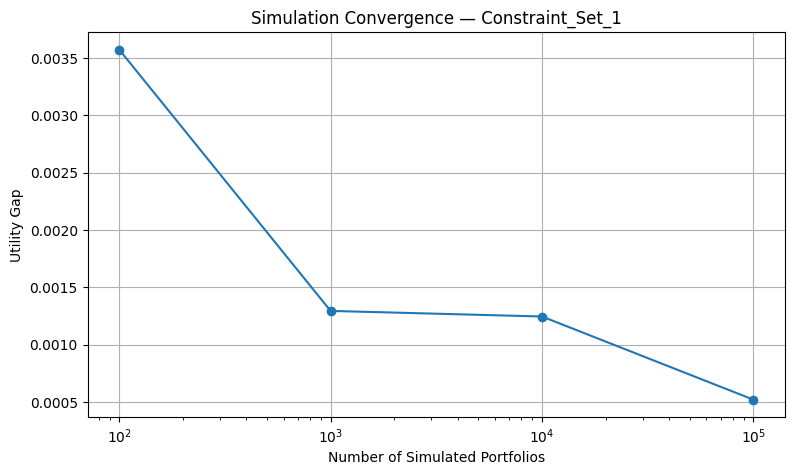

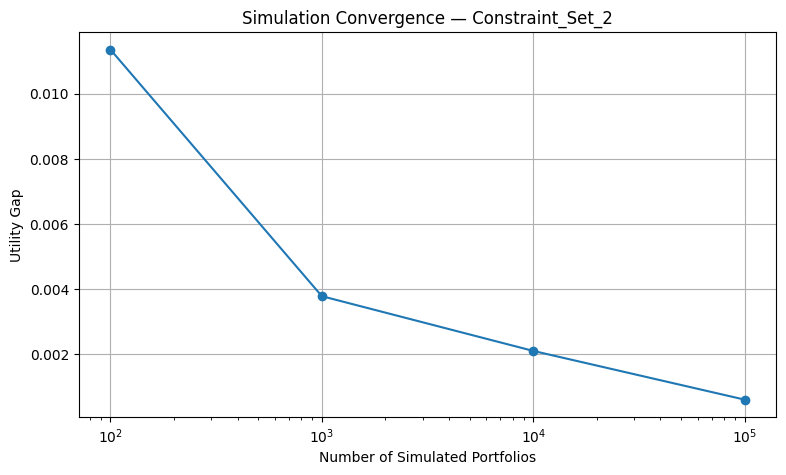

In [75]:
import matplotlib.pyplot as plt

for constraint_name in CONSTRAINT_SETS:

    subset = convergence_df[
        convergence_df["Constraint_Set"] == constraint_name
    ]

    plt.figure(figsize=(9, 5))

    plt.plot(
        subset["Simulations"],
        subset["Utility_Gap"],
        marker="o"
    )

    plt.xscale("log")
    plt.xlabel("Number of Simulated Portfolios")
    plt.ylabel("Utility Gap")
    plt.title(f"Simulation Convergence — {constraint_name}")
    plt.grid(True)

    plt.show()

seems like it takes about a 100k simulated portfolios to close the gap between the answers between that obtained using optimizer vs that we got using simulator

compare the simulated weights with optimized weights

In [76]:
for constraint_name, constraints in CONSTRAINT_SETS.items():

    optimal_w = optimized_weights[constraint_name]

    simulated_weights = simulate_portfolios(
        n_simulations=100000,
        lower_bounds=constraints["lower"],
        upper_bounds=constraints["upper"],
        n_assets=len(SELECTED_ASSETS),
        random_state=42
    )

    metrics = evaluate_portfolios(
        simulated_weights,
        mu_5.values,
        Sigma_5.values,
        delta
    )

    best_index = metrics["Utility"].idxmax()

    best_simulated_w = pd.Series(
        simulated_weights[best_index],
        index=SELECTED_ASSETS
    )

    comparison = pd.DataFrame({
        "Numerical_Optimization": optimal_w,
        "Best_Random_Simulation": best_simulated_w,
        "Absolute_Difference": (
            optimal_w - best_simulated_w
        ).abs()
    })

    print(f"\n{constraint_name}")
    display(comparison)


Constraint_Set_1


,Numerical_Optimization,Best_Random_Simulation,Absolute_Difference
0,0.000000,NaN,NaN
1,0.455321,NaN,NaN
2,0.215704,NaN,NaN
3,0.019817,NaN,NaN
4,0.309158,NaN,NaN
BAC,NaN,0.260467,NaN
GOOG,NaN,0.015362,NaN
META,NaN,0.298828,NaN
TSLA,NaN,0.002525,NaN
WMT,NaN,0.422817,NaN



Constraint_Set_2


,Numerical_Optimization,Best_Random_Simulation,Absolute_Difference
0,0.000000,NaN,NaN
1,0.300000,NaN,NaN
2,0.300000,NaN,NaN
3,0.100000,NaN,NaN
4,0.300000,NaN,NaN
BAC,NaN,0.295519,NaN
GOOG,NaN,0.093468,NaN
META,NaN,0.299081,NaN
TSLA,NaN,0.013513,NaN
WMT,NaN,0.298419,NaN


### Discussions:



The main finding is that 100,000 simulations appear sufficient to obtain very close weights under Constraint Set 2. Under Constraint Set 1, 100,000 simulations improve the result considerably, but the weights are not yet as close.


for constraint 1:
The largest improvement occurs between 100 and 1,000 simulations. The improvement between 1,000 and 10,000 is relatively small, followed by another improvement at 100,000.

constraint 2's behaviour:
Constraint Set 2 shows a steady reduction in the utility gap as the simulation count increased stair by stair.

the maximum weight difference for Constraint Set 1 increases slightly between 1,000 and 10,000 simulations.

In [77]:
for constraint_name, constraints in CONSTRAINT_SETS.items():

    optimal_w = optimized_weights[constraint_name].copy()

    # Assign the correct ticker labels to the optimizer weights.
    optimal_w.index = SELECTED_ASSETS

    simulated_weights = simulate_portfolios(
        n_simulations=100000,
        lower_bounds=constraints["lower"],
        upper_bounds=constraints["upper"],
        n_assets=len(SELECTED_ASSETS),
        random_state=42
    )

    metrics = evaluate_portfolios(
        simulated_weights,
        mu_5.values,
        Sigma_5.values,
        delta
    )

    best_index = metrics["Utility"].idxmax()

    best_simulated_w = pd.Series(
        simulated_weights[best_index],
        index=SELECTED_ASSETS
    )

    comparison = pd.DataFrame({
        "Numerical_Optimization": optimal_w,
        "Best_Random_Simulation": best_simulated_w
    })

    comparison["Absolute_Difference"] = (
        comparison["Numerical_Optimization"]
        - comparison["Best_Random_Simulation"]
    ).abs()

    print(f"\n{constraint_name}")
    display(comparison)

    print(
        "Maximum weight difference:",
        comparison["Absolute_Difference"].max()
    )

    print(
        "Mean weight difference:",
        comparison["Absolute_Difference"].mean()
    )


Constraint_Set_1


,Numerical_Optimization,Best_Random_Simulation,Absolute_Difference
TSLA,0.000000,0.002525,0.002525
WMT,0.455321,0.422817,0.032503
BAC,0.215704,0.260467,0.044762
GOOG,0.019817,0.015362,0.004455
META,0.309158,0.298828,0.010330


Maximum weight difference: 0.04476232640115893
Mean weight difference: 0.018915110394469754

Constraint_Set_2


,Numerical_Optimization,Best_Random_Simulation,Absolute_Difference
TSLA,0.000000,0.013513,0.013513
WMT,0.300000,0.298419,0.001581
BAC,0.300000,0.295519,0.004481
GOOG,0.100000,0.093468,0.006532
META,0.300000,0.299081,0.000919


Maximum weight difference: 0.013513084755174234
Mean weight difference: 0.005405233902069716


This comparision shows how much simulated result differs from numerical_optimization result for those 2 constraints.